In [4]:
from typing import List, Optional

# Panlidrome String in DP 

typically using DP, with a matrix that has meanings
- how to explain the meaning of the matrix
- how to optimize the space complexity to O(N)

The problem can be in several different variations
- not allow any modification, just check the substring from i to j, like problem 647, increment 1 only when s[i+1][j-1] = 1
- allow modification, removing is a general action, sometimes allowing insert or replace. 
  - only allow removing, problem 516, when s[i]!=s[j] the update of the dp matrix depends on dp[i+1][j] or dp[i][j-1]
  - allow all three actions, like problem 72

<b> 516 longest palindromic subsequence </b>

the problem can be converted to find the minimum cost (removing element) to make the string a palindromic one. Then the length of original str - the cost is the result

here the matrix cost is in size (n, n), cost[i][j] means the min cost of making substring from index i to index j(included) as a palindromic one.

why i starting backwards, and j starting from i+1?
- cost[i][j] relies on cost[i+1][j-1], cost[i+1][j], cost[i][j-1], i+1 should be before i, hence i should be reverse order from n-2, and j depends on previous j value, so j is starting from i+1 in incremental order 

How to interpret cost[i+1][j-1] for i+1 > j-1, for example "abbb", cost[2][3] == cost[3][2]. 
- i+1>j−1 represents the cost of making an empty substring a palindrome, which is defined as 0. This base case ensures that the algorithm works seamlessly, even when skipping characters leads to an invalid or empty substring.

In [12]:

def longestPalindromeSubseq(s: str) -> int:
    """
    same as find the smallest number of changes to make the string a palindro
    """
    n = len(s)
    # cost[i][j] means the min cost to make s[i:j+1] a palindro
    # i, j are valid index
    cost = [[0]*n for _ in range(n)]
    
    for i in range(n-2, -1, -1):
        for j in range(i+1, n):
            if s[i]==s[j]:
                # no additional cost occurred
                # same as the cost of s[i+1: j-1+1]
                cost[i][j] = cost[i+1][j-1]
            else:
                # either remove char at i+1 or at j-1
                cost[i][j] = 1 + min(cost[i+1][j], cost[i][j-1])
    print(cost)
    return n - cost[0][n-1]

In [13]:
longestPalindromeSubseq("bbbab")

[[0, 0, 0, 1, 1], [0, 0, 0, 1, 1], [0, 0, 0, 1, 0], [0, 0, 0, 0, 1], [0, 0, 0, 0, 0]]


4

another way to solve the problem by directly using matrix to save the longest subarray lenth value. In the length way, when the new char are found, we add 2 to the length because new starting and ending char are found

important step: set the matrix[i][i] to 1, means the single char itself is a valid palindrome so the length is 1

In [ ]:

def longestPalindromeSubseq(s: str) -> int:
    """
    length[i][j]: the longest subarray found between s[i:j+1]
    """
    n = len(s)
    # i, j are valid index
    length = [[0]*n for _ in range(n)]
    for i in range(n):
        # a char itself is a valid palidrome
        length[i][i] = 1
    for i in range(n-2, -1, -1):
        for j in range(i+1, n):
            if s[i]==s[j]:
                # char at i and j can be added to the existing palindrome
                length[i][j] = 2 + length[i+1][j-1]
            else:
                # either remove char at i+1 or at j-1
                length[i][j] = max(length[i+1][j], length[i][j-1])
    return length[0][n-1]

<b> 1216 valid palindrome III </b>

at most removing k charamters. The problem can be transformed into finding the minimum number of changes that can make the string as a palindrome, and then see if the change number <= k.

then the solution is similar to the problem 516

can it stop earilier?
- i tried and asked deepseak, turns out that the early stop does not work well. have to compute the steps needed for the entire string

In [4]:

def isValidPalindrome( s: str, k: int) -> bool:
    """
    at most removing k elements
    cost is to find the smallest num of elements need to remove to get a palindrome, then compared with limit k
    """
    # dp[i][j] means the mimium cost to make string from index i to j a palindrome

    n = len(s)
    cost = [[0]*n for _ in range(n)]
    # i, j is the left and right index pointer to s
    for i in range(n-2, -1, -1):
        for j in range(i+1, n):
            if s[i] == s[j]:
                cost[i][j] = cost[i+1][j-1]
            else:
                cost[i][j] = 1 + min(cost[i+1][j], cost[i][j-1])

    return cost[0][n-1] <= k


In [6]:
isValidPalindrome("abcdeca", 2)

True

<b> 680 valid palindrome II </b>

option 1: straightforward one because only allow to remove one element at most.

In [5]:

def validPalindrome(s: str) -> bool:
    """only allow to delete 0 or 1 character
    """
    left, right = 0, len(s)-1
    while left <= right:
        if s[left] != s[right]:
            one = s[left: right] # remove one char from right
            two = s[left+1: right+1] # remove one char from left
            return one==one[::-1] or two==two[::-1]
        else:
            left+=1
            right-=1
    return True
        

option 2: transform to calculate the minimum steps to make the string a valid palindrome, then check if the minimum steps <=1, but can be overkill, because the process can stop much earlier.

<b> 2330 valid palindrome IV </b>

now instead of removing char, it is replacing character to make it a valid palindrome.

2 pointers and keep track f K value is enough. similar to the problem of 680.

In [7]:

def makePalindrome(s: str) -> bool:
    """
    2 pointers
    at most change 2 times
    """
    n = len(s)
    i = 0
    j = n-1
    k = 2
    while i < j:
        if s[i]!=s[j]:
            k -= 1
            if k < 0:
                return False
        i+=1
        j-=1
    return True


<b> 1628 longest palindromic subsequence II </b>

A subsequence of a string s is considered a good palindromic subsequence if:

It is a subsequence of s.  
It is a palindrome (has the same value if reversed).  
It has an even length.  
No two consecutive characters are equal, except the two middle ones.  
For example, if s = "abcabcabb", then "abba" is considered a good palindromic subsequence, while "bcb" (not even length) and "bbbb" (has equal consecutive characters) are not.  

Given a string s, return the length of the longest good palindromic subsequence in s.



it is difficult to use the cost matrix way because the length of the subarray should be even, so i use the length matrix way.   
<i> how to enforce the result to be an even number of string: </i> 
- If not setting the length[i][i] = 1, which means a single char is not a valid palindrome, then it can help make the final result to length even.
- i in range(n-2, -1, -1) and j in range(i+1, n) so always compare with 2 different char

A smart way to keep another matrix edge, which stores the edge char of the palindrome, and then used to ensure there is no same concecutive chars in the palindrome

In [8]:

def longestPalindromeSubseq(s: str) -> int:
    """
    remove not needed char from s to construct the palindrome
    even length, and 
    no consecutive chars are equal except the middle two
    """
    n = len(s)
    # length[i][j]: the max len of making s[i:j+1] palindromic
    length = [[0]*n for _ in range(n)]
    # store the edge (leftest, rightest) char of the sub palindromic array
    # edge[i][j] means the edge of the longest palindromic subarray within the range s[i:j+1]
    edge = [[""]*n for _ in range(n)]
    for i in range(n-2, -1, -1):
        for j in range(i+1, n):
            # exclude case where consecutive char are the same
            # except for len = 2
            if s[i] == s[j] and (j-i+1 == 2 or s[i]!=edge[i+1][j-1]):
                length[i][j] = 2+length[i+1][j-1]
                edge[i][j] = s[i]
            # if no further constraints on len, consecutive char
            # length[i][j] = max(length[i+1][j], length[i][j-1])
            # but here need to update the edge accordingly
            # so separate the two case: removing element
            elif length[i+1][j] > length[i][j-1]:
                length[i][j] = length[i+1][j]
                # remove 1 element, to be as subarray in [i+1,j]
                edge[i][j] = edge[i+1][j]
            else:
                length[i][j] = length[i][j-1]
                edge[i][j] = edge[i][j-1]
    return length[0][n-1]



In [5]:
longestPalindromeSubseq("bc")

0

<b> 1771 maximize palindrom length from subsequences </b>

allow removing element as long as the order is not changed. dp[i][j] means the longest size of the palindrome found within the substring s[i: j+1]. The update value of dp[i][j] rely on its neighbors even when s[i]!=s[j].

one important thing is to ensure there are chars from two words, instead of only from one word, when constructing the palindrome.



In [8]:
def longestPalindrome(word1: str, word2: str) -> int:
    """
    concatenating the two words into one string, then transform into normal question of finding the length of the longest palindrome
    but need to ensure there are chars picked from both words. otherwise it could happen that all chars are from one words
    """
    new_word = word1 + word2
    n = len(new_word)
    l1 = len(word1)
    l2 = len(word2)
    # dp[i][j] stores the longest length of palindrome within the index range of i to j.
    dp = [[0]*n for _ in range(n)]
    max_l = 0
    for i in range(n-1, -1, -1):
        # with this sentence we can set j from i+1 to avoid potential index out of bound error when doing dp[i+1][j-1] check
        dp[i][i] = 1
        for j in range(i+1, n):
            if new_word[i] == new_word[j]:
                dp[i][j] = 2 + dp[i+1][j-1]
                # check if index from two words
                if i<l1 and l1<=j:
                    max_l = max(max_l, dp[i][j])
            else:
                dp[i][j] = max(dp[i+1][j], dp[i][j-1])
    return max_l


In [7]:
longestPalindrome("aa","bb")

0

<b> 5 longest palindromic substring </b>

dp[i][j] has value either 1 or o, means if substring s[i: j+1] is valid palindrome. substring does not include step like remove, replace, just the subset of the original string.

using a global var to keep track of the longest substring found so far

In [1]:

def longestPalindrome(s: str) -> str:

    """
    return the actual palindrome substring, not the count
    dp[i][j] means if substring s[i: j+1] is valid palindrome
    here the substring does not include step like remove, replace, just the subset of the original string
    """
    n = len(s)
    # if substring i to j is palindrome, 0 means false, 1 means yes
    dp = [[0]*n for _ in range(n)]
    # a single char itself is palindrome, but no need to loop through the matrix and initialize the value for dp[i][i] = 1 because the loop later having j starting at (i, n), which cover the case for i == j

    max_l = 0 # keep check of the max substring found as valid palindrome
    res = ""
    for i in range(n-1, -1, -1):
        for j in range(i, n):
            # new tail meets the criteria and chars in between is valid too
            # if the length of string is < 3, no need to compare the middle char, explicitly add this j-i+1<=3 because the dp[i+1][j-1] wont cover the case, for example s[3][4], -> s[4][3] is 0
            if s[i] == s[j] and (j-i+1 <=3 or dp[i+1][j-1] == 1):
                dp[i][j] = 1
                if j-i+1 > max_l:
                    max_l = j-i+1
                    res = s[i:j+1]
    return res


to optimize the space complexity from O(N^2) to O(N).  
the for loop only need to know dp[i+1][j-1] == 1, which is the value from previous loop. using an array is enough

In [9]:

def longestPalindrome(s: str) -> str:
    n = len(s)
    # if substring i to j is palindrome, 0 means false, 1 means yes
    # optimize space complexity from O(N^2) to O(N)
    prev = [0]*n
    # a single char itself is palindrome, but no need to loop through the matrix and initialize the value for dp[i][i] = 1 because the loop later having j starting at (i, n), which cover the case for i == j

    max_l = 0 # keep check of the max substring found as valid palindrome
    res = ""
    for i in range(n-1, -1, -1):
        cur = [0]*n
        for j in range(i, n):
            # new tail meets the criteria and chars in between is valid too
            # if the length of string is < 3, no need to compare the middle char, explicitly add this j-i+1<=3 because the dp[i+1][j-1] wont cover the case, for example s[3][4], -> s[4][3] is 0
            # the loop comparison only need to compare with dp[i+1][j-1], which is previous loop of i, so only using a list is enough for comparision
            if s[i] == s[j] and (j-i+1 <=3 or prev[j-1] == 1):
                cur[j] = 1
                if j-i+1 > max_l:
                    max_l = j-i+1
                    res = s[i:j+1]
        prev = cur
    return res


<b> 647 palindromic substring </b>

find the total number of valud palindromic substrings, no deletion or insertion or replacement. So using the matrix to keep track of the palindromic status and whenver found one, just increment the result value

In [2]:

def countSubstrings(s: str) -> int:
    """
    is_p matrix[i][j] if substring i to j is valid palindrome
    whenever found a panlindrome substring, the end result +1
    """
    n = len(s)
    is_p = [[0]*n for _ in range(n)]
    res = 0

    for i in range(n-1, -1, -1):
        for j in range(i, n):
            if s[i] == s[j] and (j-i+1<=3 or is_p[i+1][j-1]):
                is_p[i][j] = 1
                res+= 1
    return res


the above solution can be optmized by having two rows instead of a matrix.

prev row, initialize the last item which is is_p[n-1][n-1] to 1
curr row

In [9]:
class Solution:
    def countSubstrings(self, s: str) -> int:
        """
        is_p matrix[i][j] if substring i to j is valid palindrome
        whenever found a panlindrome substring, the end result +1
        """
        n = len(s)
        prev_row = [0]*n
        # is_p[n-1][n-1] should be 1, single char is a palindrome
        prev_row[-1] = 1
        res = 1 # because of the last item initialization

        for i in range(n-2, -1, -1):
            cur_row = [0]*n
            for j in range(i, n):
                if s[i] == s[j] and (j-i+1<=3 or prev_row[j-1]):
                    cur_row[j] = 1
                    res+= 1
            prev_row = cur_row
        return res

<b> count different palindromic subsequences </b>

now count the different / distinct palindromic subsequence, for problem 647 just count every valid one.

<b> 131. palindrome partitioning </b>

partition the string into multiple substring, each of which is a palindrome. return all the possible partition.

for returning all possible partition, using the backtracking solution.

time complexity:
-   depends on how many possible partition exists, for size N, the partition number can be Cn0 + Cn1 + ... Cn(n-1) = 2^(N-1) 
    -   for example: a_b_c: for 3 char array, the place to put partition is at most 2 places, then for each valid place, you can determine if you want to place a partition bar or not, hence 2^(N-1)
-   check palindrom takes O(N)
-   so in total O(2^(N-1) * N)

In [ ]:
class Solution:
    def partition(self, s: str) -> List[List[str]]:
        
        def helper(res, tmp, start_ind):
            if start_ind == len(s):
                res.append(tmp[:])
                return
            for i in range(start_ind, len(s)):
                if s[start_ind: i+1] == s[start_ind: i+1: -1]:
                    tmp.append(s[start_ind: i+1])
                    helper(res, tmp, i+1)
                    tmp.pop()
        def is_p(s):
            # check if s is a palindrome
            return s == s[::-1]
        res = []
        helper(res, [], 0)
        return res

<b> 72 edit distance </b>

now instead of one single string, here are two strings for comparision, the valid actions are
- insert
- delete
- replace

the matrix cost is in shape (m+1, n+1), where the index representing the length of the word.  
cost[i][j] means the min cost of converting the first i char of word_1 to first j char of word_2.  

cost[m][n] is the result of min cost to convert word 1 to word2

In [ ]:

def minDistance(word1: str, word2: str) -> int:
    """DP way
    f(i, j) for min cost of converting first i char ofs word1 to first j chars of word2
    if word1[i]==word2[j] => f(i,j)=f(i-1,j-1)
    else
    f(i,j)=1+min(f(i,j-1), f(i-1,j), f(i-1,j-1))
    f(i,j-1): insert operation, same as f(i+1,j), symmentric
    f(i-1,j): delete operation, 
    f(i-1,j-1): replace operation
    time complexity O(M*N)
    """

    m = len(word1)
    n = len(word2)
    # here the number represents for actual number of char
    cost = [[0]*(n+1) for _ in range(m+1)] # (m+1)*(n+1) matrix
    for i in range(m+1):
        # words with i chars convert into words with 0 chars, need i step
        cost[i][0] = i
    for j in range(n+1):
        cost[0][j] = j

    # here the i, j reprents the char count
    for i in range(1, m+1):
        for j in range(1, n+1):
            if word1[i-1] == word2[j-1]: # since i,j are counts, index should be i-1, j-1
                # attention: i,j in cost matrix represents the actual count number of chars
                cost[i][j] = cost[i-1][j-1]
            else:
                cost[i][j] = 1 + min(cost[i-1][j], cost[i][j-1], cost[i-1][j-1])

    return cost[m][n]


<b> 1143 longest common subsequence </b>  
Given two strings text1 and text2, return the length of their longest common subsequence. If there is no common subsequence, return 0.  A subsequence of a string is a new string generated from the original string with some characters (can be none) deleted without changing the relative order of the remaining characters. => can delete unnecessary chars

comparing two words, similar to 72, for substring, Not every letter in the strings has to be used, but letters cannot be rearranged.

matrix[i][j] means the the number of common chars between the first ith char of word1 and first jth chars of text2. i, j in the matrix represents the actual count of chars ,so the value range is [0, m/n]. This also takes care of the edge case when comparing first pair of chars and they are not the same.

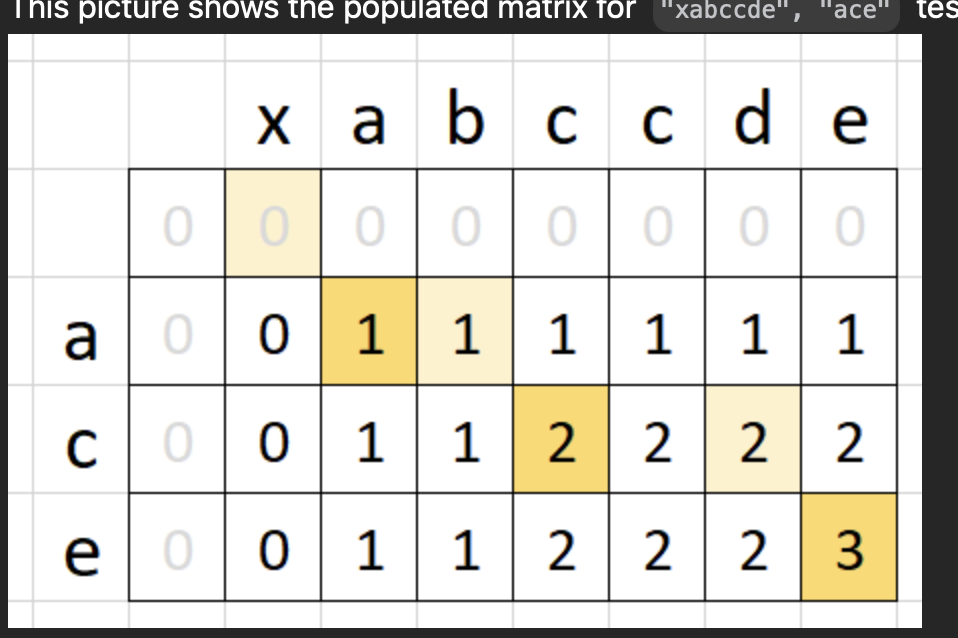

In [3]:

def longestCommonSubsequence(text1: str, text2: str) -> int:
    """
    dp in shape m+1, n+1, m,n are the length of text1 text2
    dp[i][j] means the number of common chars between first i elements of text1 and first j elements of text2
    i, j are the length of characters, so the value range
    is from 0 to the length
    """

    m = len(text1)
    n = len(text2)
    dp = [[0]*(n+1) for _ in range(m+1)] # (m+1, n+1) shape
    for i in range(m):
        for j in range(n):
            if text1[i] == text2[j]:
                # index in dp means the actual length
                # if current pair of char equals, increment the size,
                dp[i+1][j+1] = 1 + dp[i][j]
            else:
                # either not including the comparision of ith char from word 1 nor jth char from word2
                dp[i+1][j+1] = max(dp[i+1][j], dp[i][j+1])
    return dp[m][n]

<b> 1400 construct K pandlinrome strings </b>

more a math problem.

the construction of string does not need to keep the original char order, so not the same as other palindrome problem. As long as the char in the string is used to make the K string, then it is good. Hence the count is more important.

if a char has odd count,  each of them form its own palindrome substring, it can pair with other char with even count or just be itself, depending on the K value. however if the odd count > K, then there will be some char left over not used up, hence False at that case.

largest K is N, at that case each char itself stands as a palindrome, which is valid too.

In [3]:
from collections import Counter
def canConstruct(s: str, k: int) -> bool:
    """
    count each char in s
    get the number of char with odd count and even count
    if odd_count <=k and k<=n, there will always be enough solution
    -   each odd char in different palindrome, it can pair or not pair with other char with even count.
    -   k should be <= n, otherwise not enough char to form the substring

    -   odd_char_count: the lower limit of palindrome count
    -   len(s): the upper limit of the palindrome count
    """
    count = Counter(s)
    odd_char_count = sum(1 for c, v in count.items() if v%2==1)
    return odd_char_count <= k and k <=len(s)